# Punto 1 FINAL - MNIST + CIFAR-10 (corre las celdas en orden, sin saltar)


Version oficial diffusers train_unconditional.py + fixes GitHub #6222 (generator por batch) y cleanfid #46 (num_workers=0 batch 16).


### 0 Setup


In [1]:
%pip install -q diffusers accelerate datasets torchvision clean-fid torch-fidelity
import torch
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)


device: cuda


### 1 Datos (MNIST L 1ch, CIFAR RGB 3ch). num_workers=0 para no congelar Colab.


In [2]:
from datasets import load_dataset
from torchvision import transforms
import torch
def get_dl(name):
    if name=="mnist":
        tf=transforms.Compose([transforms.Resize(32), transforms.ToTensor(), transforms.Normalize([0.5],[0.5])])
        ds=load_dataset("ylecun/mnist", split="train")
        ds=ds.with_transform(lambda ex: {"image":[tf(i.convert("L")) for i in ex["image"]]})
    else:
        tf=transforms.Compose([transforms.RandomHorizontalFlip(), transforms.ToTensor(), transforms.Normalize([0.5,0.5,0.5],[0.5,0.5,0.5])])
        ds=load_dataset("uoft-cs/cifar10", split="train")
        col="img" if "img" in ds.column_names else "image"
        if col!="image": ds=ds.rename_column(col,"image")
        ds=ds.with_transform(lambda ex: {"image":[tf(i.convert("RGB")) for i in ex["image"]]})
    return torch.utils.data.DataLoader(ds, batch_size=64, shuffle=True, num_workers=0)
print("dl OK")


dl OK


### 2 UNet 3down=3up + squaredcos_cap_v2 (es el cosine en diffusers, ver docs).


In [3]:
from diffusers import UNet2DModel, DDPMScheduler
def get_model(ch):
    d=(64,128,256) if ch==1 else (128,256,512)
    m=UNet2DModel(sample_size=32, in_channels=ch, out_channels=ch, layers_per_block=2, block_out_channels=d, down_block_types=("DownBlock2D","AttnDownBlock2D","DownBlock2D"), up_block_types=("UpBlock2D","AttnUpBlock2D","UpBlock2D"))
    s=DDPMScheduler(num_train_timesteps=1000, beta_schedule="squaredcos_cap_v2")
    return m,s
print("model OK")


model OK


### 3 Train (modelo+datos mismo device, opt despues de .to).


In [4]:
import os, json, torch, tqdm

def train_run(dl, model, sched, steps, out, resume=True, ckpt_every=1000, lr=2e-4, amp=True):
    device = "cuda" if torch.cuda.is_available() else "cpu"
    model.to(device).train()
    opt = torch.optim.AdamW(model.parameters(), lr=lr)
    scaler = torch.amp.GradScaler("cuda", enabled=(amp and device == "cuda"))
    start = 0
    history = []

    # Reanudar si existe un checkpoint propio. Si es un state_dict viejo, solo carga pesos.
    if resume and os.path.exists(out):
        ckpt = torch.load(out, map_location=device, weights_only=False)
        if isinstance(ckpt, dict) and "model" in ckpt:
            model.load_state_dict(ckpt["model"])
            if "opt" in ckpt:
                opt.load_state_dict(ckpt["opt"])
            start = int(ckpt.get("step", 0))
            history = ckpt.get("history", [])
            print(f"reanudo en el paso {start} desde {out}")
        else:
            model.load_state_dict(ckpt)
            print(f"cargo pesos sueltos de {out}; empiezo en el paso 0")

    n_batches = len(dl)
    print(f"{steps} pasos objetivo, batch {dl.batch_size}, ~{steps/n_batches:.1f} epocas, device {device}")

    if start >= steps:
        print(f"{out} ya tiene {start} pasos; no hay nada que entrenar")
        return history

    it = iter(dl)
    pbar = tqdm.tqdm(total=steps, initial=start, desc=os.path.basename(out))
    step = start

    while step < steps:
        try:
            batch = next(it)
        except StopIteration:
            it = iter(dl)
            batch = next(it)

        clean = batch["image"].to(device, non_blocking=True)
        noise = torch.randn_like(clean)
        t = torch.randint(0, sched.config.num_train_timesteps, (clean.shape[0],), device=device).long()
        noisy = sched.add_noise(clean, noise, t)

        opt.zero_grad(set_to_none=True)
        with torch.autocast("cuda", dtype=torch.float16, enabled=scaler.is_enabled()):
            pred = model(noisy, t).sample
            loss = torch.nn.functional.mse_loss(pred.float(), noise.float())

        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(opt)
        scaler.update()

        step += 1
        loss_value = loss.item()
        history.append((step, loss_value))
        pbar.update(1)
        pbar.set_postfix(loss=f"{loss_value:.4f}", epoch=step // n_batches)

        if step % ckpt_every == 0 or step == steps:
            ckpt = {"model": model.state_dict(), "opt": opt.state_dict(), "step": step, "history": history}
            tmp = out + ".tmp"
            torch.save(ckpt, tmp)
            os.replace(tmp, out)
            with open(out.replace(".pt", "_history.json"), "w") as f:
                json.dump(history, f)
            print(f"checkpoint {step}/{steps} -> {out}")

    pbar.close()
    print("OK", out, "pasos:", step)
    return history

### 4 Eval (limpia carpeta antes, generator en pipeline.device - fix GitHub #6222, muestra en pantalla).


In [5]:
from diffusers import DDPMPipeline, DDPMScheduler, DDIMScheduler
from diffusers.utils import make_image_grid
import torch, os, glob, shutil
from PIL import Image
import matplotlib.pyplot as plt

def eval_run(model, sched, prefix, ngen=1000):
    device = "cuda" if torch.cuda.is_available() else "cpu"
    model.to(device)
    pipe = DDPMPipeline(unet=model, scheduler=sched).to(device)
    base_cfg = dict(pipe.scheduler.config)  # config original; no encadenar scheduler sobre scheduler

    folder = os.path.abspath("gen_" + prefix)
    if os.path.exists(folder):
        shutil.rmtree(folder)
    os.makedirs(folder)

    # DDPM estocastico y DDIM deterministico; DPM-Solver no convergio con este modelo.
    jobs = [("ddpm", DDPMScheduler, 20), ("ddim", DDIMScheduler, 20)]
    comp = []
    for name, Sch, steps in jobs:
        pipe.scheduler = Sch.from_config(base_cfg)
        g = torch.Generator(device=pipe.device).manual_seed(0)
        ims = pipe(batch_size=4, num_inference_steps=steps, generator=g).images
        comp.append(ims[0])

    plt.figure(figsize=(6, 3))
    for i, (im, (name, _, steps)) in enumerate(zip(comp, jobs)):
        plt.subplot(1, 2, i + 1)
        plt.imshow(im)
        plt.title(f"{prefix} {name} ({steps} pasos)")
        plt.axis("off")
    plt.tight_layout()
    plt.show()

    # Generacion final con DDIM: las 1000 imagenes que consumen las metricas.
    pipe.scheduler = DDIMScheduler.from_config(base_cfg)
    k = 0
    b = 0
    while k < ngen:
        g = torch.Generator(device=pipe.device).manual_seed(1000 + b)
        ims = pipe(batch_size=16, num_inference_steps=20, generator=g).images
        for im in ims:
            im.save(os.path.join(folder, "%04d.png" % k))
            k += 1
            if k >= ngen:
                break
        b += 1
    print(prefix, "gen", k, "en", folder)

    files = sorted(glob.glob(os.path.join(folder, "*.png")))
    if len(files) >= 16:
        grid = make_image_grid([Image.open(f) for f in files[:16]], rows=4, cols=4)
        plt.figure(figsize=(6, 6))
        plt.imshow(grid)
        plt.title("grid " + prefix)
        plt.axis("off")
        plt.show()
    return pipe

### 5 Entrena MNIST (15000 pasos, ~16 epocas).


In [6]:
STEPS_MNIST = 15000  # para una prueba corta usa 100; el checkpoint reanuda solo
dl_mnist = get_dl("mnist")
model_m, sched_m = get_model(1)
train_run(dl_mnist, model_m, sched_m, STEPS_MNIST, "ddpm-mnist.pt")

README.md:   0%|          | 0.00/6.97k [00:00<?, ?B/s]

mnist/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 15.6MB            

mnist/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

mnist/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 2.60MB            

mnist/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/60000 [00:00<?, ? examples/s]

... (29 outputs left out)

checkpoint 14000/15000 -> ddpm-mnist.pt


ddpm-mnist.pt: 100%|██████████| 15000/15000 [48:59<00:00,  5.10it/s, epoch=15, loss=0.0255]

checkpoint 15000/15000 -> ddpm-mnist.pt
OK ddpm-mnist.pt pasos: 15000


[(1, 1.0033706426620483),
 (2, 0.625249981880188),
 (3, 0.4279896914958954),
 (4, 0.2890550196170807),
 (5, 0.2546583116054535),
 (6, 0.2071387767791748),
 (7, 0.18849553167819977),
 (8, 0.242503821849823),
 (9, 0.21681739389896393),
 (10, 0.18774457275867462),
 (11, 0.1552707552909851),
 (12, 0.1632162630558014),
 (13, 0.12767243385314941),
 (14, 0.15365678071975708),
 (15, 0.13330364227294922),
 (16, 0.15287494659423828),
 (17, 0.14993631839752197),
 (18, 0.1165233701467514),
 (19, 0.1280839890241623),
 (20, 0.10787321627140045),
 (21, 0.10501664131879807),
 (22, 0.10106945037841797),
 (23, 0.09345915168523788),
 (24, 0.12407650798559189),
 (25, 0.09565581381320953),
 (26, 0.10705290734767914),
 (27, 0.1072860062122345),
 (28, 0.10684674978256226),
 (29, 0.08024273067712784),
 (30, 0.09361685812473297),
 (31, 0.07913222908973694),
 (32, 0.08542126417160034),
 (33, 0.08915141969919205),
 (34, 0.0671510174870491),
 (35, 0.08202899992465973),
 (36, 0.07644485682249069),
 (37, 0.10016541

### 6 Muestrea MNIST (llena gen_mnist, aqui nace el fix del assert).


  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

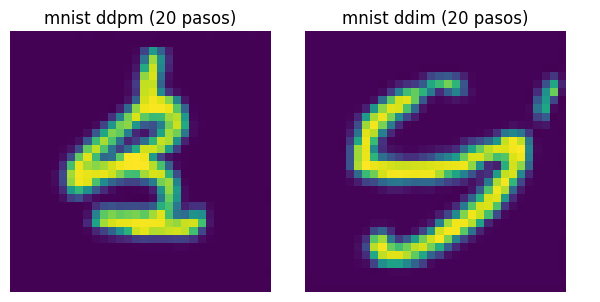

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

... (54 outputs left out)

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

mnist gen 1000 en /content/gen_mnist


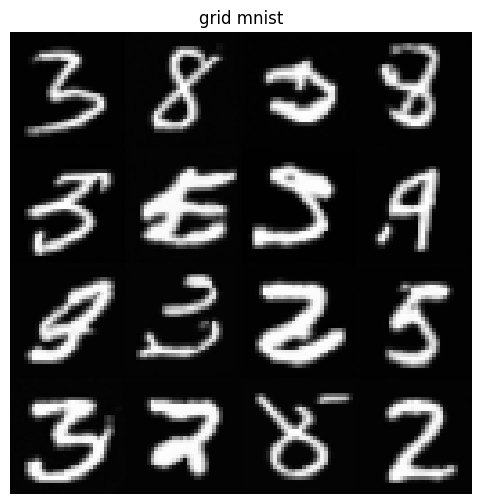

In [7]:
pipe_m=eval_run(model_m, sched_m, "mnist", 1000)


### 7 Metricas MNIST (cleanfid #46: num_workers=0 batch_size=16 para no CUDNN error).


In [8]:
from cleanfid import fid
import torch, os, glob, shutil
from datasets import load_dataset

folder = os.path.abspath("gen_mnist")
rows = sorted(glob.glob(os.path.join(folder, "*.png")))
print("gen:", len(rows))
assert len(rows) > 0, "gen_mnist vacia: corre eval_run de MNIST antes"

real = os.path.abspath("real_mnist")
if os.path.exists(real):
    shutil.rmtree(real)
os.makedirs(real, exist_ok=True)
r = load_dataset("ylecun/mnist", split="test").select(range(1000))
for j, ex in enumerate(r):
    ex["image"].resize((32, 32)).save(os.path.join(real, "%04d.png" % j))
print("real:", len(os.listdir(real)))

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("FID clean-fid:", fid.compute_fid(folder, real, device=device, num_workers=0, batch_size=16))

# IS no es una metrica estandar para MNIST en gris; se reporta solo como referencia.
import torch_fidelity
metrics = torch_fidelity.calculate_metrics(
    input1=folder, input2=real,
    cuda=torch.cuda.is_available(),
    isc=True, fid=True, kid=True, prc=True,
    kid_subset_size=min(100, len(rows) - 1),
)
print(metrics)

gen: 1000
real: 1000


/usr/local/lib/python3.13/dist-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


compute FID between two folders
Found 1000 images in the folder /content/gen_mnist


FID gen_mnist : 100%|██████████| 63/63 [00:10<00:00,  5.93it/s]


Found 1000 images in the folder /content/real_mnist


FID real_mnist : 100%|██████████| 63/63 [00:09<00:00,  6.51it/s]


FID clean-fid: 31.109544074081384


Creating feature extractor "inception-v3-compat" with features ['logits_unbiased', '2048']
Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/weights-inception-2015-12-05-6726825d.pth
100%|██████████| 91.2M/91.2M [00:00<00:00, 204MB/s]
Extracting features from input1
Looking for samples non-recursivelty in "/content/gen_mnist" with extensions png,jpg,jpeg
Found 1000 samples
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:431: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
Processing samples:   0%|         

{'inception_score_mean': 1.8187620939366702, 'inception_score_std': 0.07257506252624354, 'frechet_inception_distance': 32.932900481358985, 'kernel_inception_distance_mean': 0.022930352687835692, 'kernel_inception_distance_std': 0.006044633935040052, 'precision': 0.5879999995231628, 'recall': 0.7400000095367432, 'f_score': 0.6553012082624424}


Precision: 0.588
Recall: 0.74
F-score: 0.6553012


### 8 Entrena CIFAR-10 (15000 pasos, ~19 epocas). Cambios vs MNIST: 3ch, dim 128, flip.


In [9]:
STEPS_CIFAR = 15000  # 15000 pasos ~19 epocas; sube si el tiempo de Colab lo permite
dl_cifar = get_dl("cifar")
model_c, sched_c = get_model(3)
train_run(dl_cifar, model_c, sched_c, STEPS_CIFAR, "ddpm-cifar.pt")

README.md:   0%|          | 0.00/5.16k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  120MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 23.9MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/50000 [00:00<?, ? examples/s]

... (29 outputs left out)

checkpoint 14000/15000 -> ddpm-cifar.pt


ddpm-cifar.pt: 100%|██████████| 15000/15000 [1:55:12<00:00,  2.17it/s, epoch=19, loss=0.0403]

checkpoint 15000/15000 -> ddpm-cifar.pt
OK ddpm-cifar.pt pasos: 15000


[(1, 1.1801044940948486),
 (2, 0.9435315132141113),
 (3, 0.6616640090942383),
 (4, 0.6263751983642578),
 (5, 0.43735450506210327),
 (6, 0.407245010137558),
 (7, 0.30228060483932495),
 (8, 0.33441489934921265),
 (9, 0.243432879447937),
 (10, 0.2660665512084961),
 (11, 0.22654464840888977),
 (12, 0.2185993194580078),
 (13, 0.194810152053833),
 (14, 0.21251985430717468),
 (15, 0.18546175956726074),
 (16, 0.1574842929840088),
 (17, 0.18796059489250183),
 (18, 0.20676854252815247),
 (19, 0.18205824494361877),
 (20, 0.18503019213676453),
 (21, 0.16461753845214844),
 (22, 0.1510668843984604),
 (23, 0.1237950474023819),
 (24, 0.13018544018268585),
 (25, 0.1506909728050232),
 (26, 0.1406131237745285),
 (27, 0.13727262616157532),
 (28, 0.1499353051185608),
 (29, 0.12044557183980942),
 (30, 0.15148404240608215),
 (31, 0.13976678252220154),
 (32, 0.14332428574562073),
 (33, 0.15334977209568024),
 (34, 0.10079079866409302),
 (35, 0.0981236919760704),
 (36, 0.10637097805738449),
 (37, 0.110769078135

### 9 Genera, muestrea y calcula metricas CIFAR.


  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

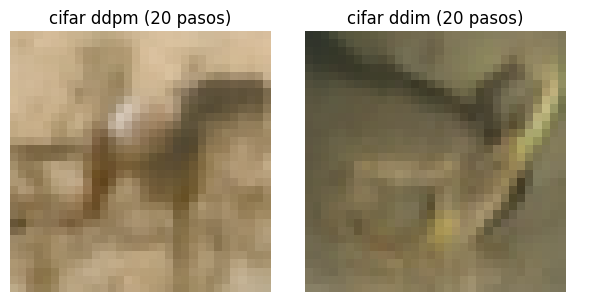

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

... (54 outputs left out)

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

cifar gen 1000 en /content/gen_cifar


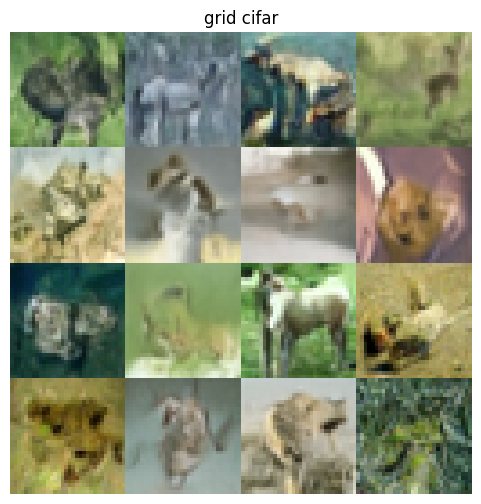

In [13]:
pipe_c = eval_run(model_c, sched_c, "cifar", 1000)

In [14]:
from cleanfid import fid
import torch, os, glob, shutil
from datasets import load_dataset

folder = os.path.abspath("gen_cifar")
rows = sorted(glob.glob(os.path.join(folder, "*.png")))
print("gen:", len(rows))
assert len(rows) > 0, "gen_cifar vacia: corre eval_run de CIFAR antes"

real = os.path.abspath("real_cifar")
if os.path.exists(real):
    shutil.rmtree(real)
os.makedirs(real, exist_ok=True)
r = load_dataset("uoft-cs/cifar10", split="test").select(range(1000))
col = "img" if "img" in r.column_names else "image"
for j, ex in enumerate(r):
    ex[col].save(os.path.join(real, "%04d.png" % j))
print("real:", len(os.listdir(real)))

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("FID clean-fid:", fid.compute_fid(folder, real, device=device, num_workers=0, batch_size=16))

import torch_fidelity
metrics = torch_fidelity.calculate_metrics(
    input1=folder, input2=real,
    cuda=torch.cuda.is_available(),
    isc=True, fid=True, kid=True, prc=True,
    kid_subset_size=min(100, len(rows) - 1),
)
print(metrics)

gen: 1000
real: 1000


/usr/local/lib/python3.13/dist-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


compute FID between two folders
Found 1000 images in the folder /content/gen_cifar


FID gen_cifar : 100%|██████████| 63/63 [00:09<00:00,  6.97it/s]


Found 1000 images in the folder /content/real_cifar


FID real_cifar : 100%|██████████| 63/63 [00:08<00:00,  7.63it/s]


FID clean-fid: 95.35962353971013


Creating feature extractor "inception-v3-compat" with features ['logits_unbiased', '2048']
Extracting features from input1
Looking for samples non-recursivelty in "/content/gen_cifar" with extensions png,jpg,jpeg
Found 1000 samples
Processing samples
Extracting features from input2
Looking for samples non-recursivelty in "/content/real_cifar" with extensions png,jpg,jpeg
Found 1000 samples
Processing samples
Inception Score: 6.04854 ± 0.487174
Frechet Inception Distance: 91.05826
Kernel Inception Distance: 0.03950927 ± 0.006113646
Creating feature extractor "vgg16" with features ['fc2_relu']
Extracting features from input1
Looking for samples non-recursivelty in "/content/gen_cifar" with extensions png,jpg,jpeg
Found 1000 samples
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:431: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to 

{'inception_score_mean': 6.048539624011522, 'inception_score_std': 0.4871740335179283, 'frechet_inception_distance': 91.05826091088579, 'kernel_inception_distance_mean': 0.03950927495956421, 'kernel_inception_distance_std': 0.006113645653873741, 'precision': 0.781000018119812, 'recall': 0.3449999988079071, 'f_score': 0.4785879241023261}


Precision: 0.781
Recall: 0.345
F-score: 0.4785879
